In [1]:
%cd "/Users/annetteschaudt/Documents/UZH shit/Data Analysis with Python/DAwP Project/Python-Project-HS26-Criminality-and-Minimum-Wage/Group_project_part_annette"
%pwd

import pandas as pd

import sys
!{sys.executable} -m pip install matplotlib

import matplotlib.pyplot as plt

/Users/annetteschaudt/Documents/UZH shit/Data Analysis with Python/DAwP Project/Python-Project-HS26-Criminality-and-Minimum-Wage/Group_project_part_annette

[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: pip3.12 install --upgrade pip


In [2]:
data = pd.read_csv("Crime_Pop_clean.csv")
print(data.head())

             Canton  Year         Type of Residence  Resident Population  \
0            Aargau  2010  Ständige Wohnbevölkerung                79369   
1  Basel-Landschaft  2010  Ständige Wohnbevölkerung                30893   
2       Basel-Stadt  2010  Ständige Wohnbevölkerung                24488   
3              Bern  2010  Ständige Wohnbevölkerung               120344   
4          Freiburg  2010  Ständige Wohnbevölkerung                36620   

   Total Residential Population  Percentage of Total Resident Population  \
0                       1006333                                 7.886952   
1                       1006333                                 3.069859   
2                       1006333                                 2.433389   
3                       1006333                                11.958666   
4                       1006333                                 3.638955   

  Age group  Number of Accused Persons  AccusedRate  
0     20-29                     

In [3]:
print(data.head())

             Canton  Year         Type of Residence  Resident Population  \
0            Aargau  2010  Ständige Wohnbevölkerung                79369   
1  Basel-Landschaft  2010  Ständige Wohnbevölkerung                30893   
2       Basel-Stadt  2010  Ständige Wohnbevölkerung                24488   
3              Bern  2010  Ständige Wohnbevölkerung               120344   
4          Freiburg  2010  Ständige Wohnbevölkerung                36620   

   Total Residential Population  Percentage of Total Resident Population  \
0                       1006333                                 7.886952   
1                       1006333                                 3.069859   
2                       1006333                                 2.433389   
3                       1006333                                11.958666   
4                       1006333                                 3.638955   

  Age group  Number of Accused Persons  AccusedRate  
0     20-29                     

Text(0, 0.5, 'Accused Rate')

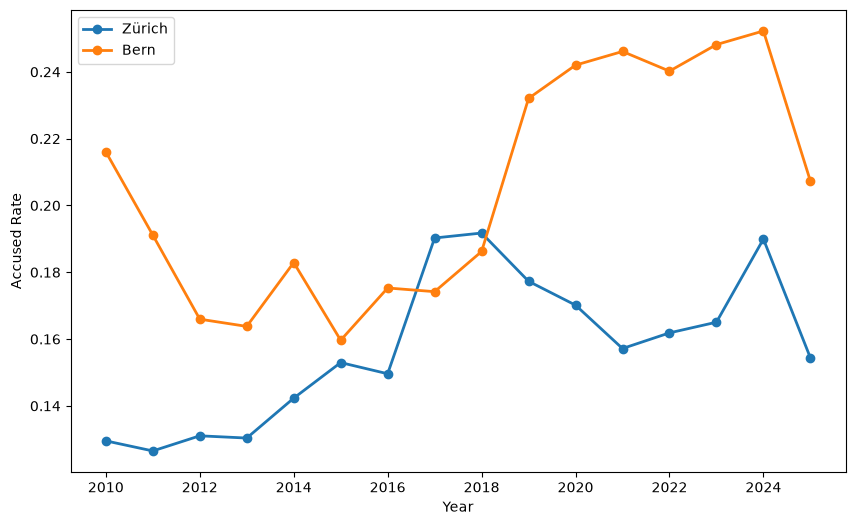

In [4]:
#creating example

canton1 = 'Zürich'
canton2 = 'Bern'

subset = data[data['Canton'].isin([canton1, canton2])] #extracts a subset of your merged dataset by filtering for rows where the value in the 'Kanton' column matches either canton1 or canton2

plt.figure(figsize=(10, 6)) #created canvas with dimensions 10 (x-axis), 6(y-axis)

for canton in [canton1, canton2]:
  canton_data = subset[subset['Canton'] == canton]
  plt.plot(
      canton_data['Year'], canton_data['AccusedRate'],
      marker='o', linewidth=2, #circle for datapoints connecting with line (2-pixel thick)
      label=canton) #lable with cantons 

plt.legend() #creating a legend

plt.xlabel('Year')
plt.ylabel('Accused Rate')



In [5]:
#preparation for creating a loop

unique_cantons = data['Canton'].unique()
print(unique_cantons)

#creating touples of cantons (no doubles)
import itertools

canton_pairs = list(itertools.combinations(unique_cantons, 2)) #itertools.combinations(..., 2) for paring every item with every other item in the list in groups of 2, ensuring that no canton is paired with itself

print(canton_pairs)

<ArrowStringArray>
[          'Aargau', 'Basel-Landschaft',      'Basel-Stadt',
             'Bern',         'Freiburg',             'Genf',
           'Luzern',        'Neuenburg',        'Solothurn',
       'St. Gallen',          'Thurgau',            'Waadt',
           'Wallis',           'Zürich']
Length: 14, dtype: str
[('Aargau', 'Basel-Landschaft'), ('Aargau', 'Basel-Stadt'), ('Aargau', 'Bern'), ('Aargau', 'Freiburg'), ('Aargau', 'Genf'), ('Aargau', 'Luzern'), ('Aargau', 'Neuenburg'), ('Aargau', 'Solothurn'), ('Aargau', 'St. Gallen'), ('Aargau', 'Thurgau'), ('Aargau', 'Waadt'), ('Aargau', 'Wallis'), ('Aargau', 'Zürich'), ('Basel-Landschaft', 'Basel-Stadt'), ('Basel-Landschaft', 'Bern'), ('Basel-Landschaft', 'Freiburg'), ('Basel-Landschaft', 'Genf'), ('Basel-Landschaft', 'Luzern'), ('Basel-Landschaft', 'Neuenburg'), ('Basel-Landschaft', 'Solothurn'), ('Basel-Landschaft', 'St. Gallen'), ('Basel-Landschaft', 'Thurgau'), ('Basel-Landschaft', 'Waadt'), ('Basel-Landschaft', 'Wallis')

In [6]:
#only keeping pairs of which one canton at least introduced minimum wage laws at some point in time
#minimum wage introduced in Neuenburg, Jura, Genf, Tessin, Basel-Stadt --> we only have Neuenburg, Genf, Basel-Stadt in our dataset

target_cantons = ["Neuenburg", "Genf", "Basel-Stadt"]

# Filtering canton_pairs list
combinations = [
    pair for pair in canton_pairs
    if any(canton in target_cantons for canton in pair)] #any(...) checks if at least one of the cantons in the current pair is present, only keeps those


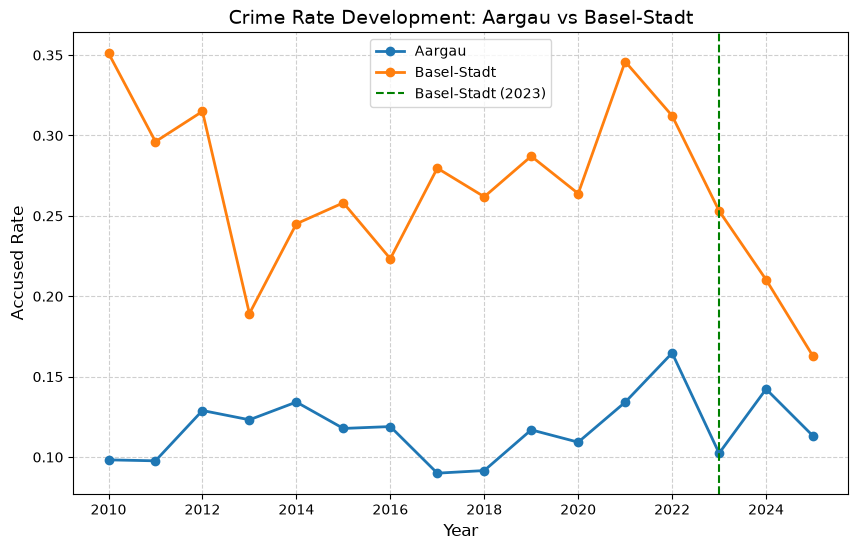

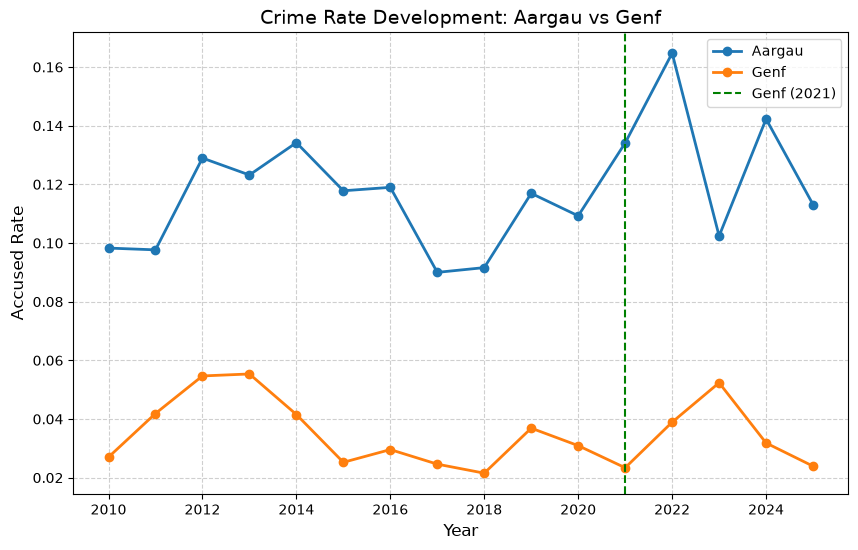

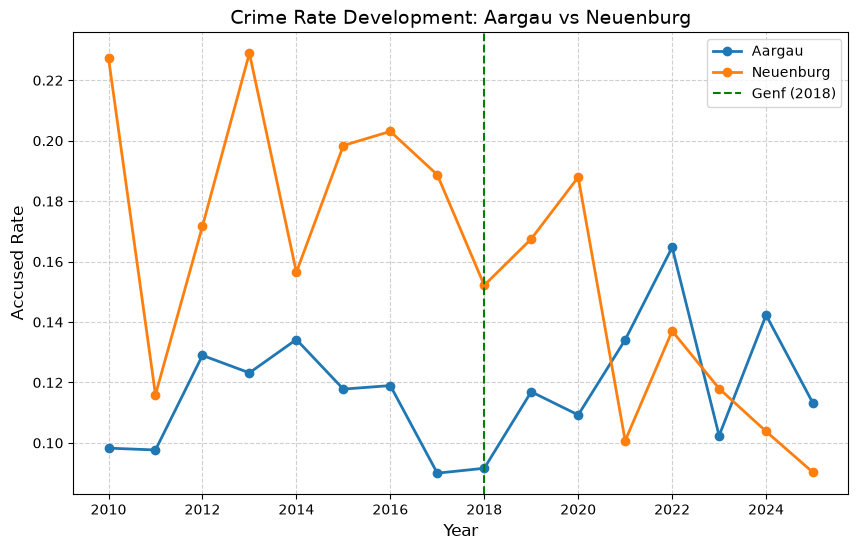

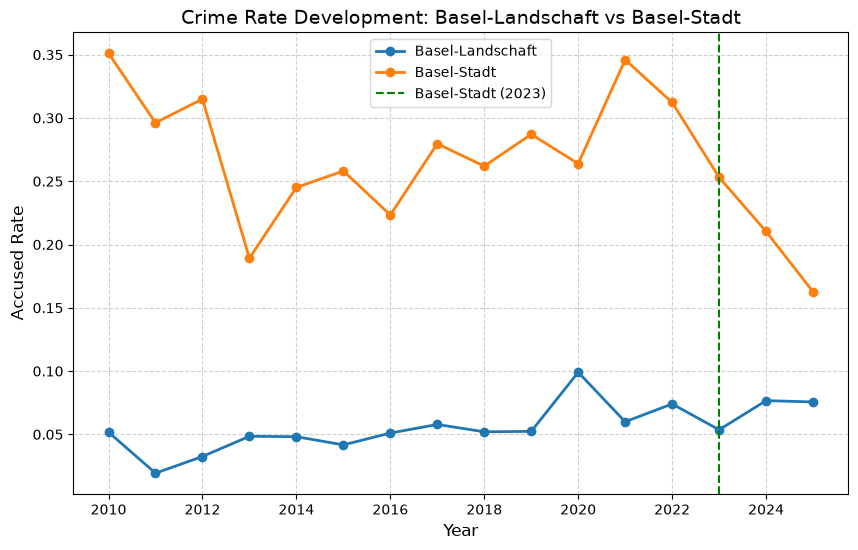

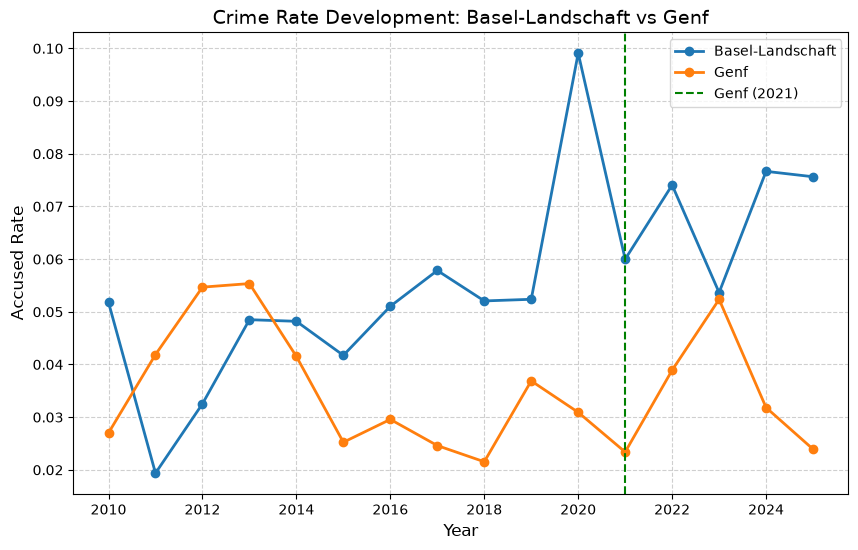

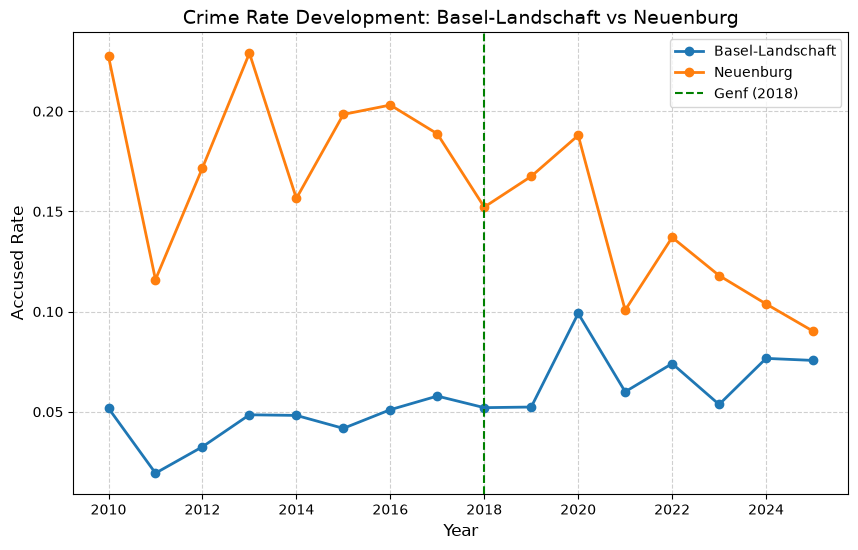

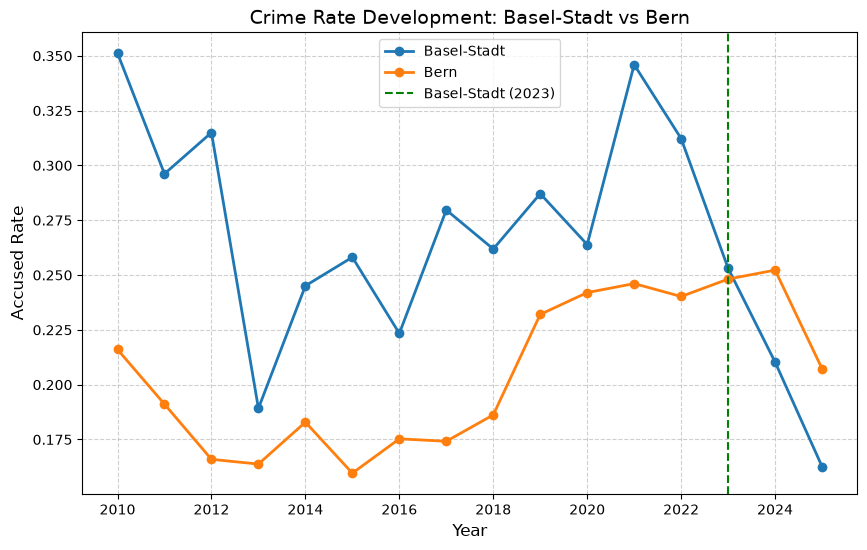

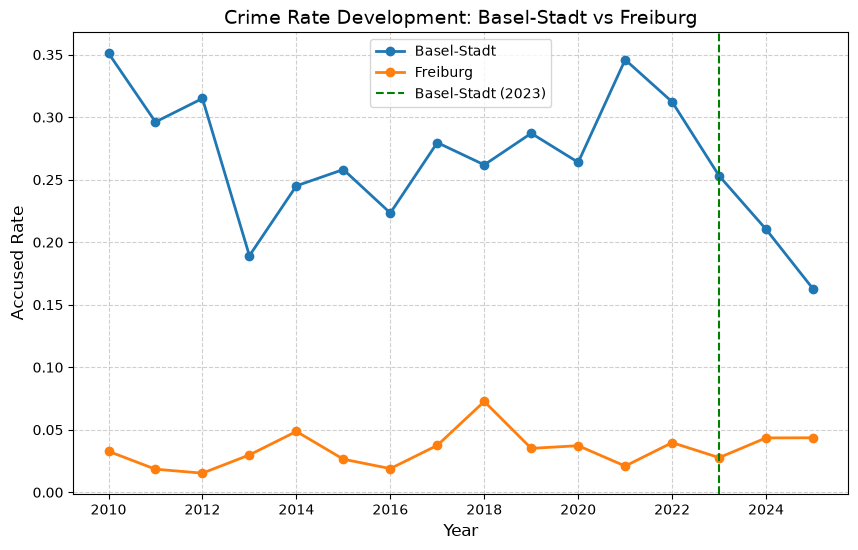

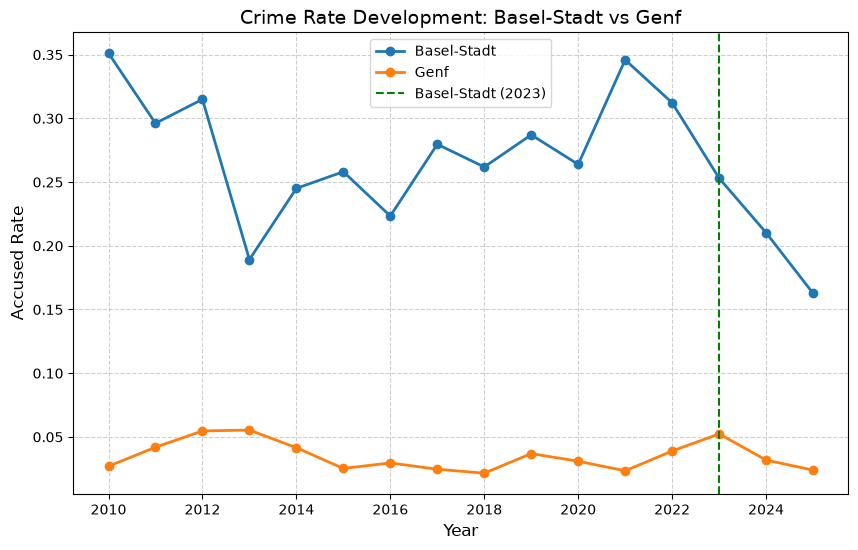

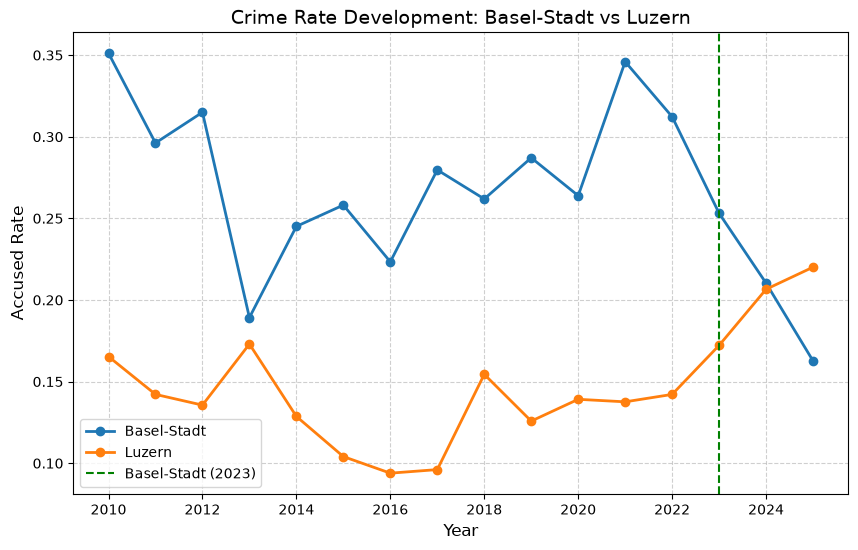

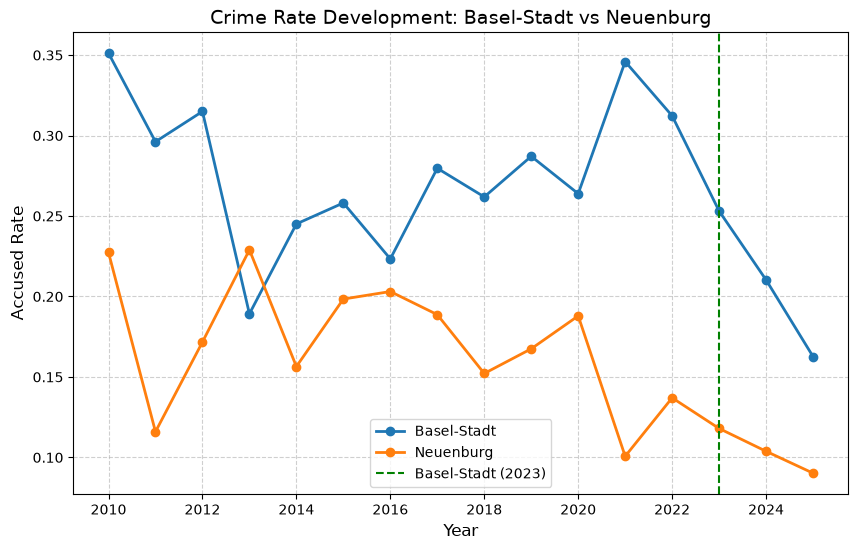

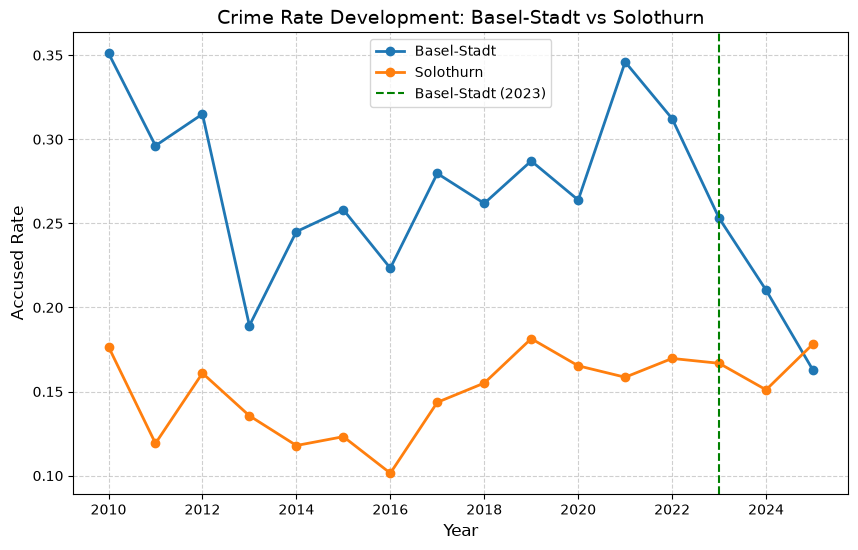

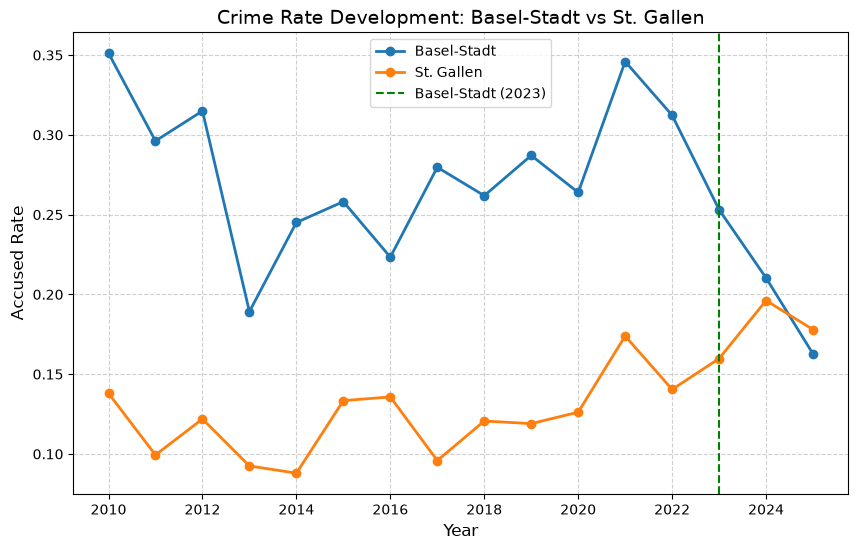

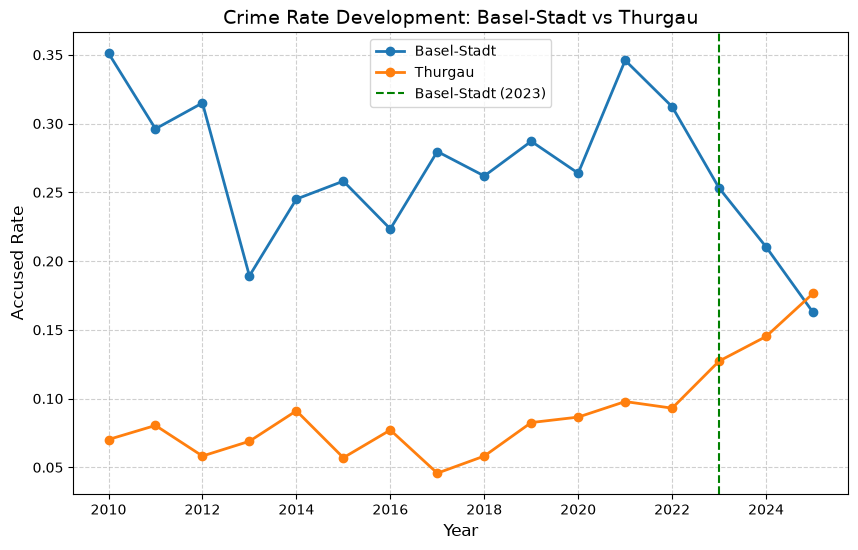

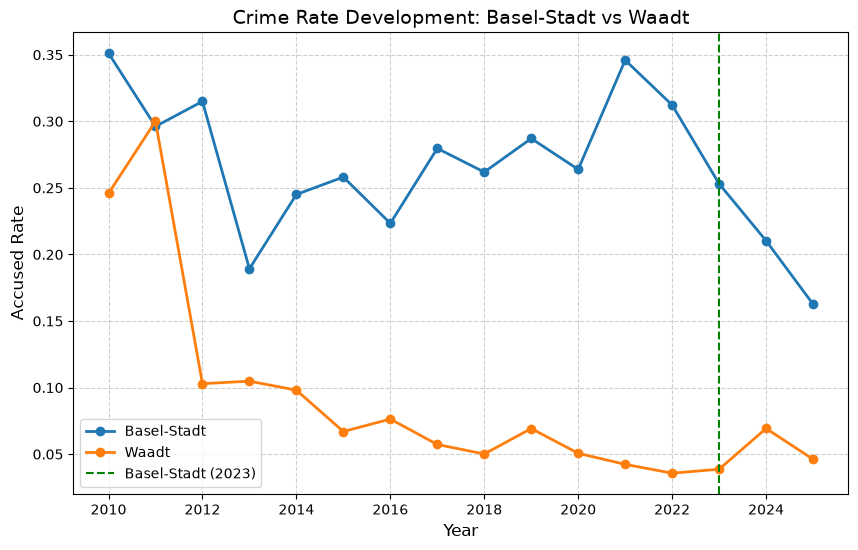

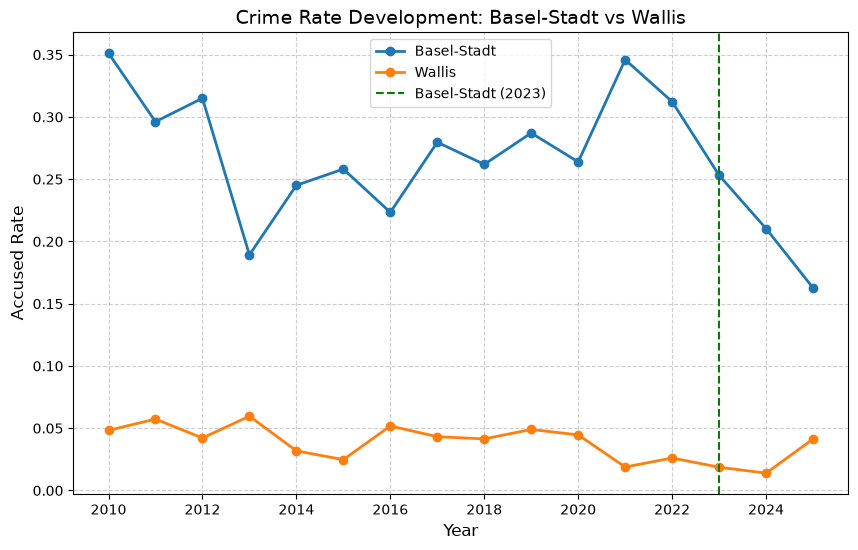

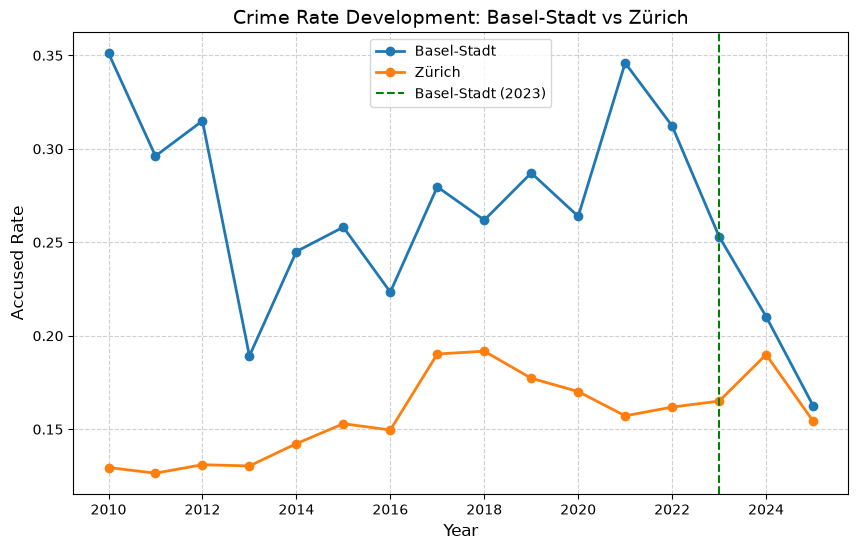

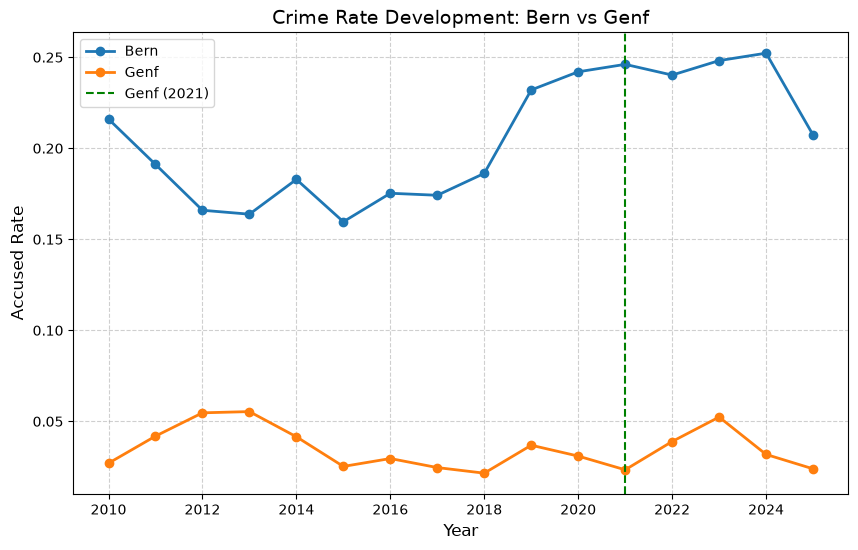

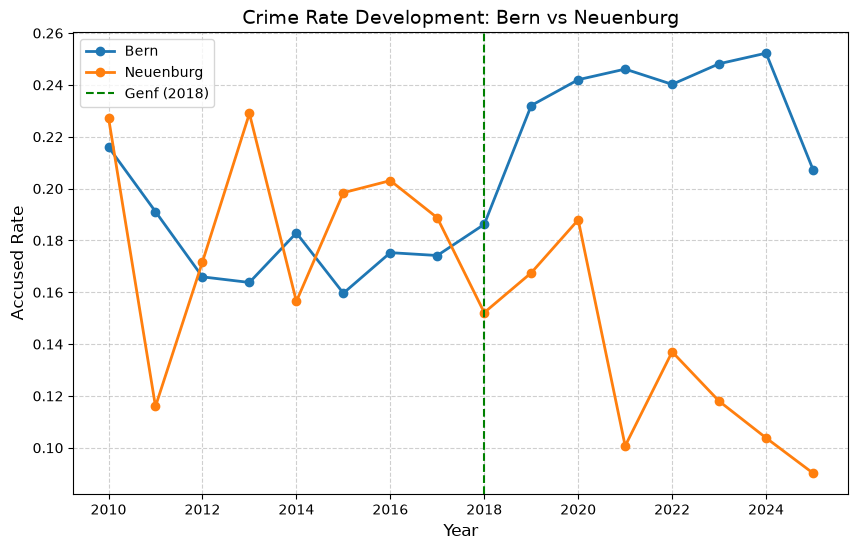

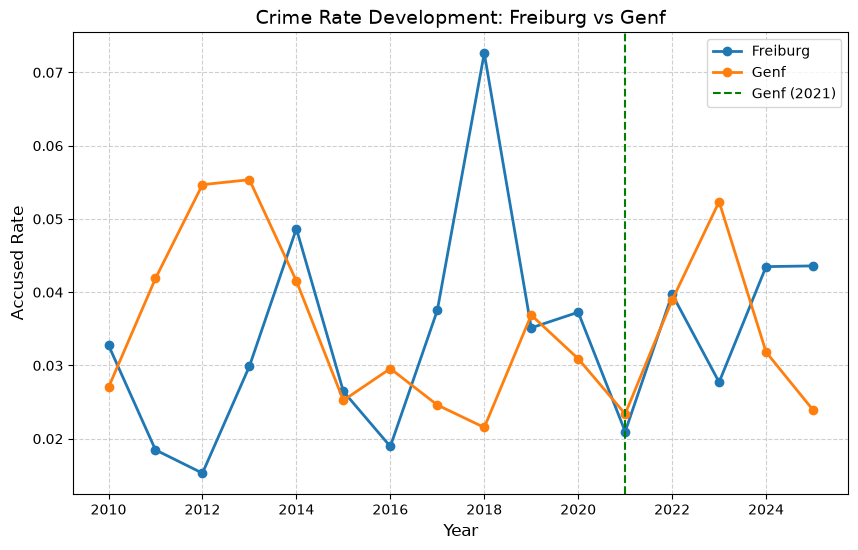

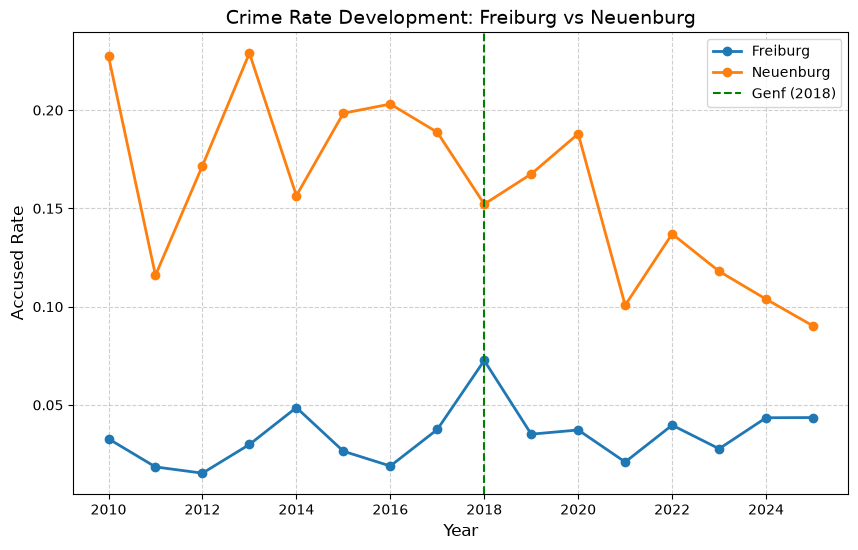

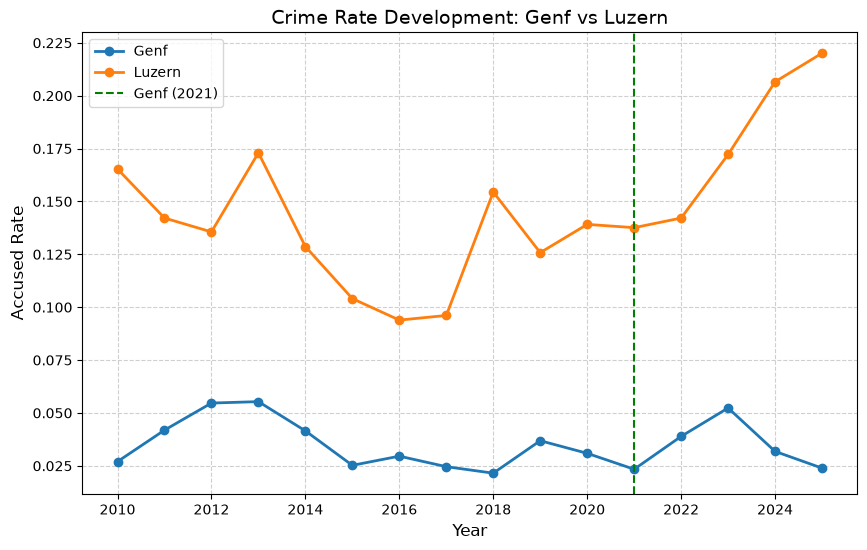

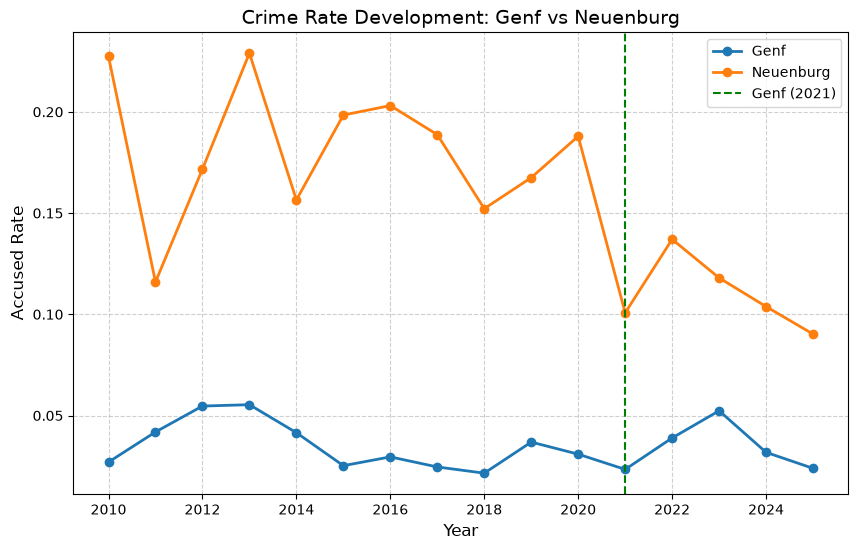

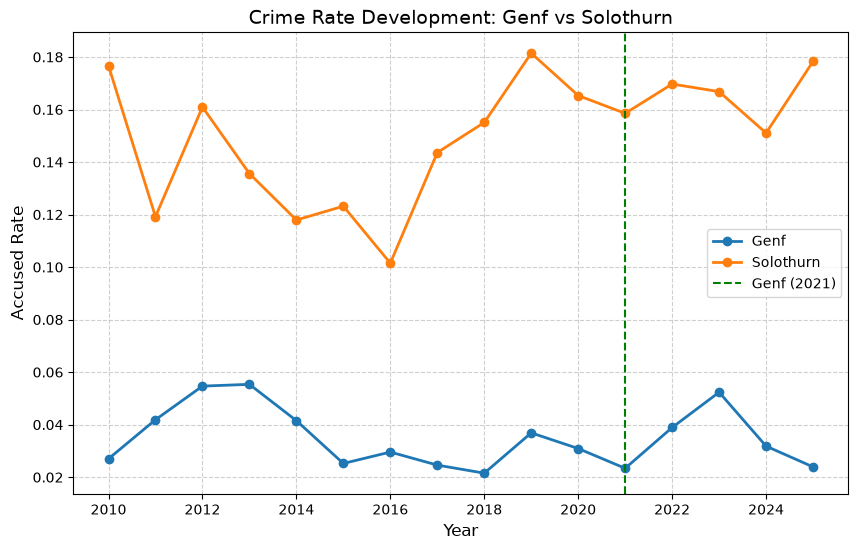

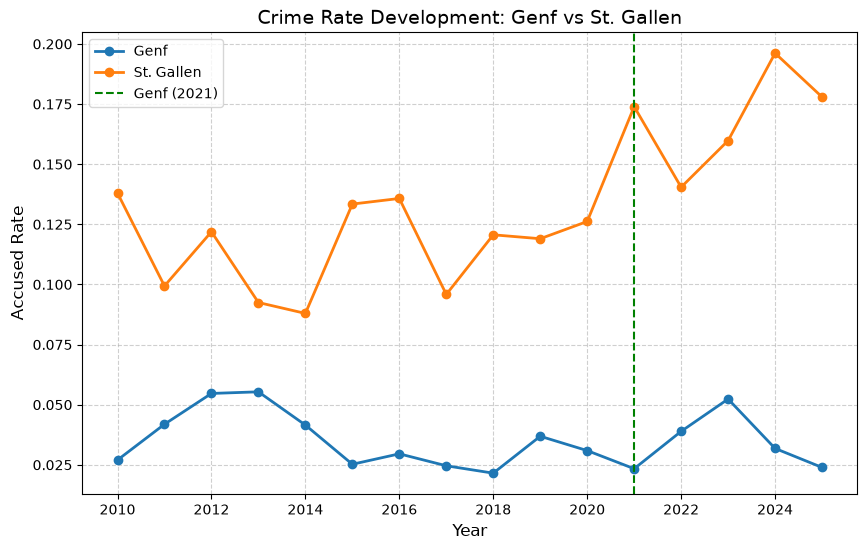

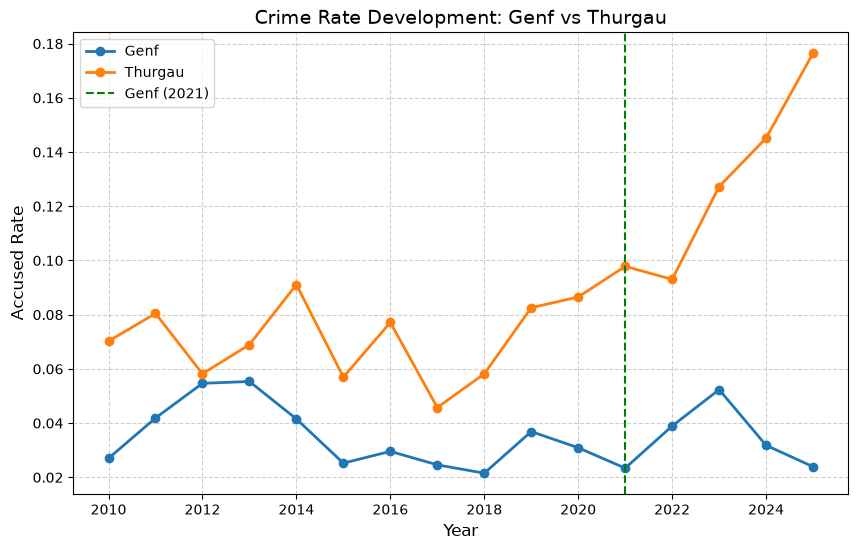

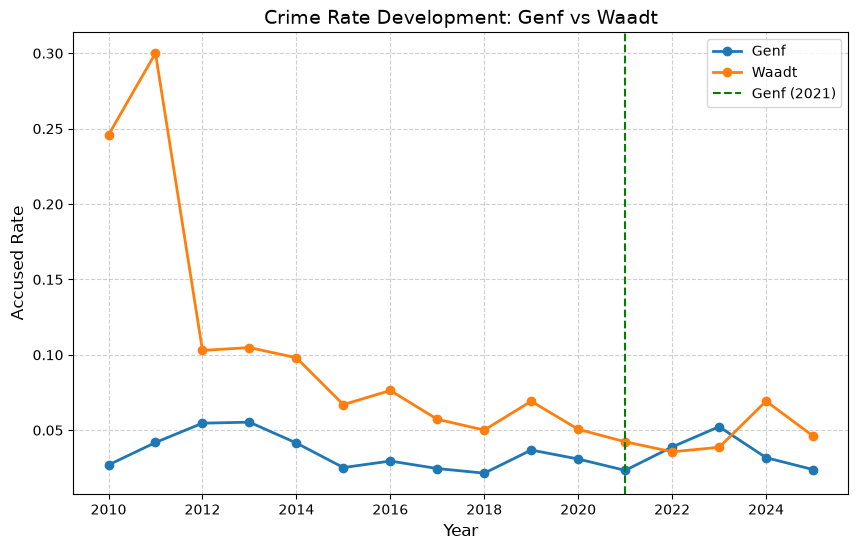

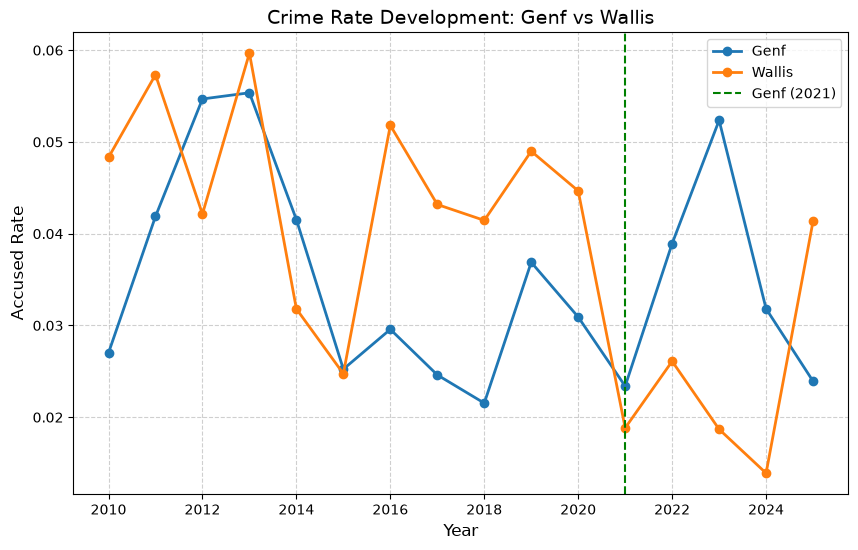

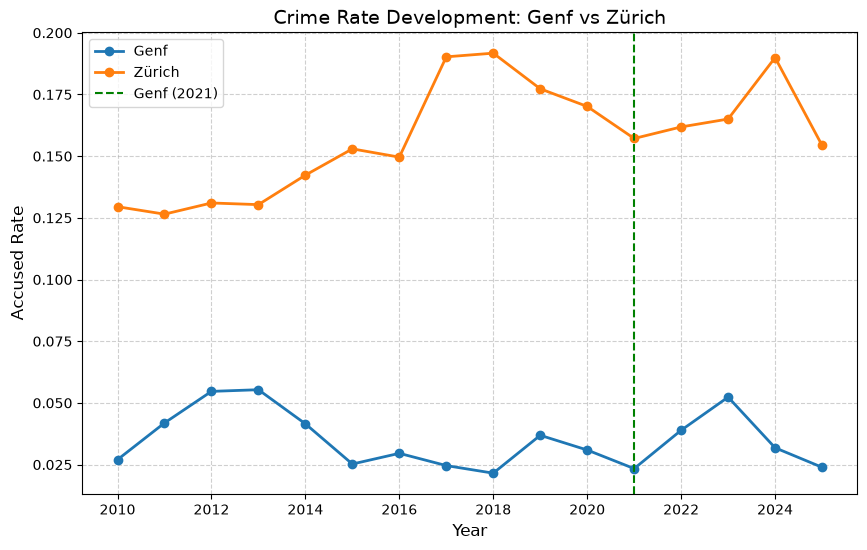

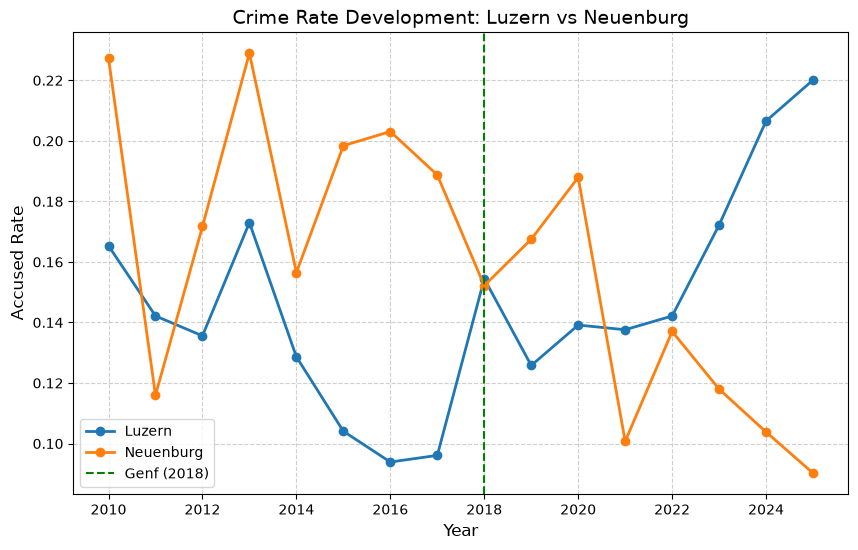

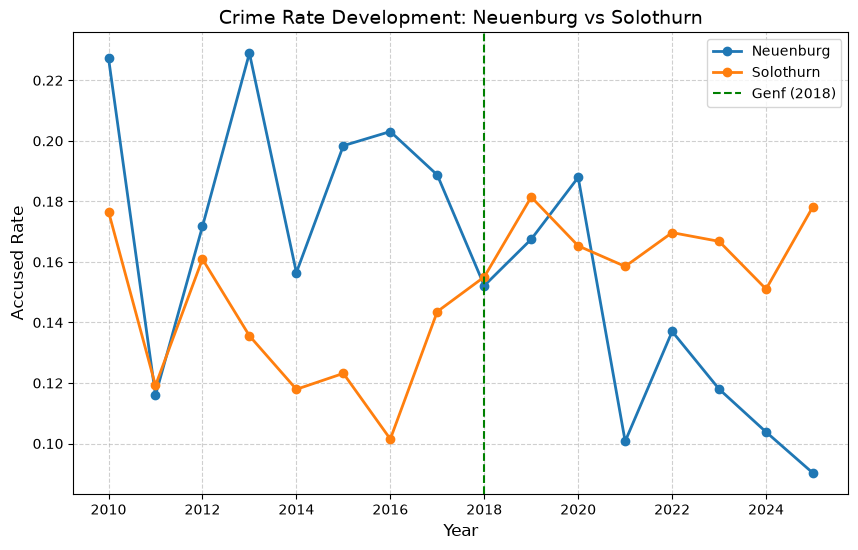

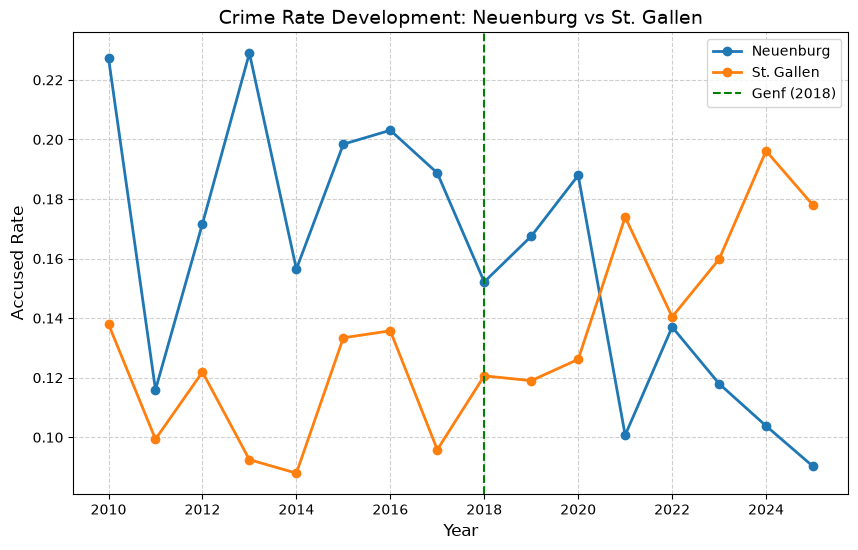

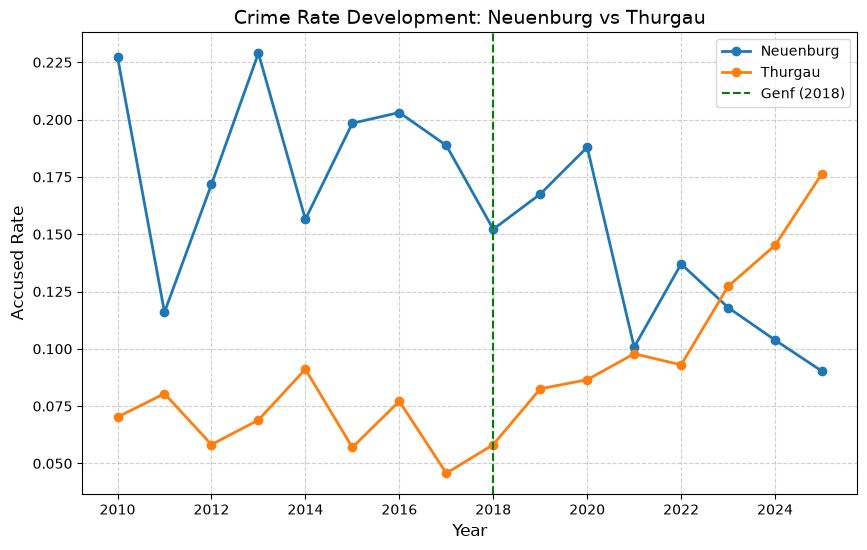

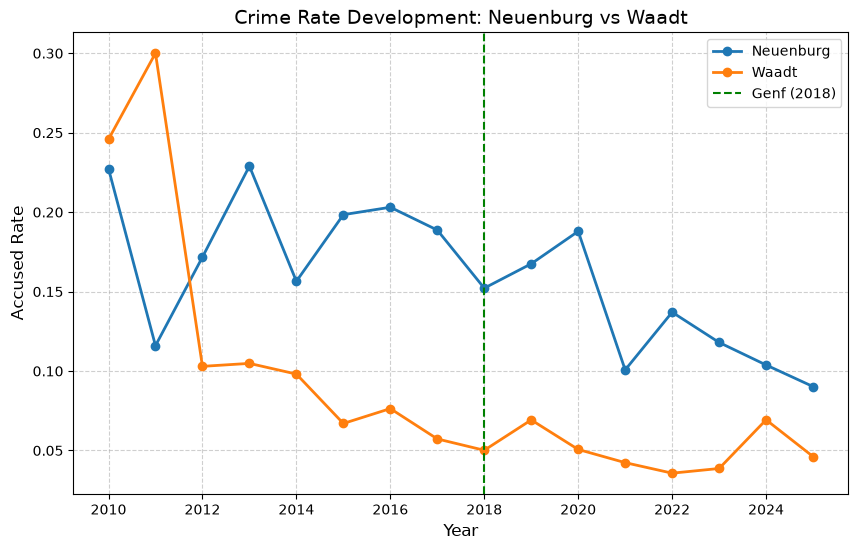

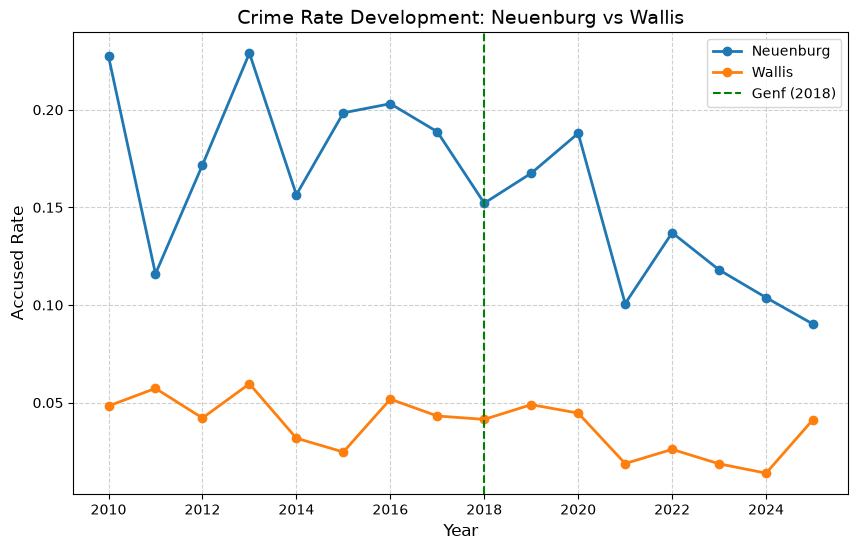

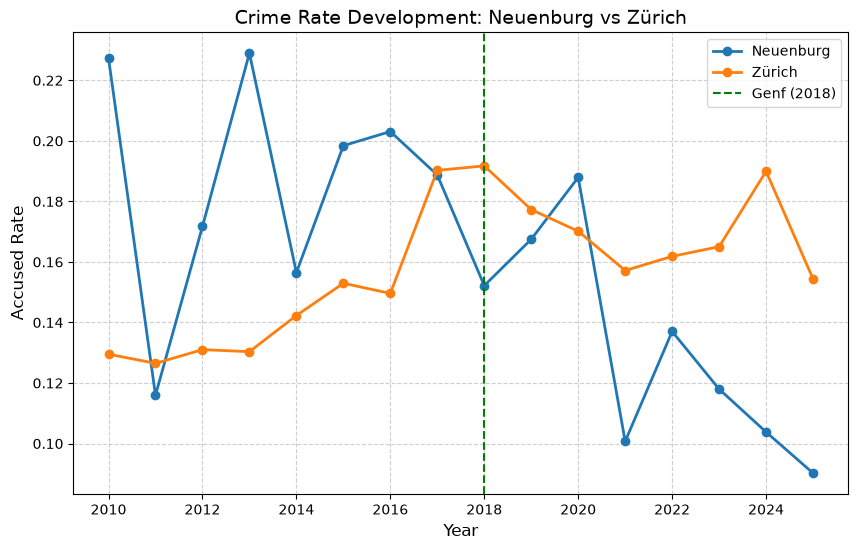

In [9]:
for canton1, canton2 in combinations:
  
  # 1. Filtering subset for the current pair of cantons
  subset = data[data['Canton'].isin([canton1, canton2])]

  # 2. Creating canvas
  plt.figure(figsize=(10, 6))

  # 3. Ploting both cantons onto same graph
  for canton in [canton1, canton2]:
    canton_data = subset[subset['Canton'] == canton]
    plt.plot(
        canton_data['Year'], 
        canton_data['AccusedRate'],
        marker='o', 
        linewidth=2, 
        label=canton)
  if 'Basel-Stadt' in [canton1, canton2]: #adding dotted line for minimum-wage-introduction
    plt.axvline(
      x=2023,
      color='green',
      linestyle='--',
      linewidth=1.5,
      label='Basel-Stadt (2023)')
  elif 'Genf' in [canton1, canton2]:
    plt.axvline(
      x=2021,
      color='green',
      linestyle='--',
      linewidth=1.5,
      label='Genf (2021)')
  elif 'Neuenburg' in [canton1, canton2]:
    plt.axvline(
      x=2018,
     color='green',
      linestyle='--',
      linewidth=1.5,
      label='Genf (2018)')


  

  # 4. Add titles, labels, and show the plot
  plt.title(f'Crime Rate Development: {canton1} vs {canton2}', fontsize=14)
  plt.xlabel('Year', fontsize=12)
  plt.ylabel('Accused Rate', fontsize=12)
  plt.legend()
  plt.grid(True, linestyle='--', alpha=0.6)
  plt.show()